# A. Data Loading. #

In [13]:
#-- Import Library. --#
from google.colab import drive
import os
#-- Mount Google Drive to the standard root directory. --#
drive.mount('/content/drive')
#-- Define the base path to your Lab04 folder on Google Drive. --#
base_dir = '/content/drive/My Drive/Courses (Units)/Applied Machine Learning (COS30082)/Laboratory/Lab04 - CNNs'
#-- Set seg_train and seg_test as variables. --#
seg_train = os.path.join(base_dir, 'seg_train')
seg_test = os.path.join(base_dir, 'seg_test')
#-- Verify the paths and check the classes inside the training folder. --#
print("Train path:", seg_train)
print("Test path:", seg_test)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Train path: /content/drive/My Drive/Courses (Units)/Applied Machine Learning (COS30082)/Laboratory/Lab04 - CNNs/seg_train
Test path: /content/drive/My Drive/Courses (Units)/Applied Machine Learning (COS30082)/Laboratory/Lab04 - CNNs/seg_test


# B. Exploratory Data Analysis. #

## 2.1 Number of Images in the Training and Testing. ##

In [14]:
#-- Geenral Information about training dataset. --#
train_count = sum([len(files) for r, d, files in os.walk(seg_train)])
test_count = sum([len(files) for r, d, files in os.walk(seg_test)])
#-- Print the size of the seg_train. --#
print(f"Total training images: {train_count}")
print(f"Total testing images: {test_count}")

Total training images: 14034
Total testing images: 3000


## 2.2 Image Metadata. ##

In [15]:
import os
from PIL import Image
#-- Get a sample image from the training dataset. --#
sample_path = os.path.join(seg_train, 'buildings', os.listdir(os.path.join(seg_train, 'buildings'))[0])
img = Image.open(sample_path)
print(f"- Image Resolution: {img.size[0]} x {img.size[1]} pixels")
print(f"- Color Channels: {len(img.getbands())}")
print(f"- File Format: {img.format}")
print(f"- File Size: {os.path.getsize(sample_path) / 1024:.2f} KB")

- Image Resolution: 150 x 150 pixels
- Color Channels: 3
- File Format: JPEG
- File Size: 14.30 KB


## 2.3 Label Distribution. ##

--- CLASS DISTRIBUTION ---
- buildings: 2191 images
- forest: 2271 images
- glacier: 2404 images
- mountain: 2512 images
- sea: 2274 images
- street: 2382 images
---------------------------


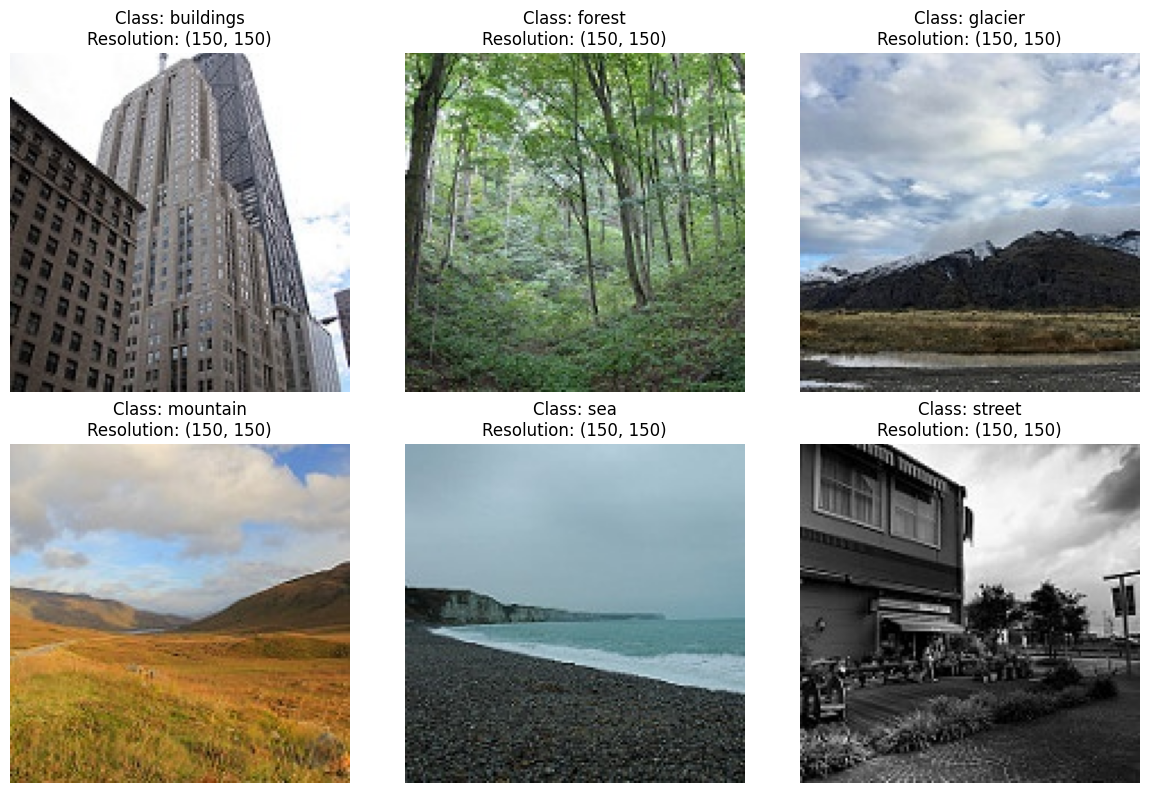

In [16]:

import os
import matplotlib.pyplot as plt
from PIL import Image
#-- Analyze the number of images per class (Class Distribution). --#
print("--- CLASS DISTRIBUTION ---")
class_names = sorted(os.listdir(seg_train))
class_counts = {}
for name in class_names:
    path = os.path.join(seg_train, name)
    if os.path.isdir(path):
        count = len(os.listdir(path))
        class_counts[name] = count
        print(f"- {name}: {count} images")

#-- Visualize sample images from each class (Sample Image Grid). --#
print("-" * 27)
plt.figure(figsize=(12, 8))
for i, name in enumerate(class_names):
    path = os.path.join(seg_train, name)
    if os.path.isdir(path):
        img_name = os.listdir(path)[0]
        img_path = os.path.join(path, img_name)

        img = Image.open(img_path)
        plt.subplot(2, 3, i + 1)
        plt.imshow(img)
        plt.title(f"Class: {name}\nResolution: {img.size}")
        plt.axis('off')

plt.tight_layout()
plt.show()

## 2.4 Quality and Variances. ##

In [17]:
import os
import numpy as np
from PIL import Image
pixel_sums, pixel_squared_sums, total_pixels = np.zeros(3), np.zeros(3), 0
#-- Take 20 images ine ach folder to calculate. --#
for class_name in sorted(os.listdir(seg_train)):
    class_path = os.path.join(seg_train, class_name)
    if os.path.isdir(class_path):
        files = os.listdir(class_path)[:20]
        for img_name in files:
            if img_name.lower().endswith(('png', 'jpg', 'jpeg')):
                with Image.open(os.path.join(class_path, img_name)) as img:
                    img_np = np.array(img.convert('RGB')) / 255.0
                    total_pixels += img_np.shape[0] * img_np.shape[1]
                    pixel_sums += img_np.sum(axis=(0, 1))
                    pixel_squared_sums += (img_np ** 2).sum(axis=(0, 1))

mean = pixel_sums / total_pixels
std = np.sqrt((pixel_squared_sums / total_pixels) - (mean ** 2))

print(f"Mean (RGB): {mean}")
print(f"Std (RGB): {std}")

Mean (RGB): [0.43457341 0.45929799 0.45111446]
Std (RGB): [0.27892554 0.27164093 0.29389689]


## 2.5 Visual Inspection. ##

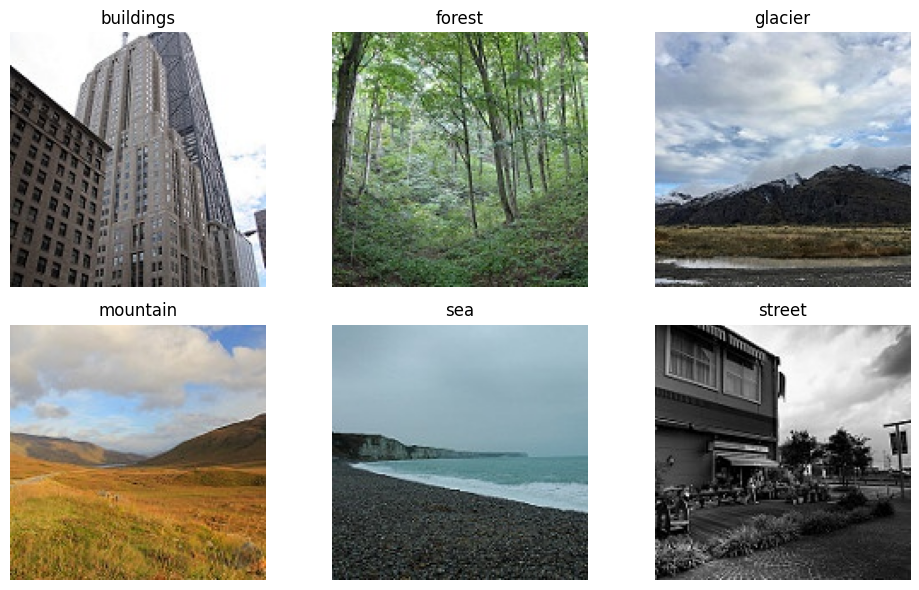

In [18]:
import os
import matplotlib.pyplot as plt
from PIL import Image
#-- Visualize a sample image from each class. --#
class_names = sorted(os.listdir(seg_train))
plt.figure(figsize=(10, 6))

for i, class_name in enumerate(class_names):
    class_path = os.path.join(seg_train, class_name)
    if os.path.isdir(class_path):
        img_name = os.listdir(class_path)[0]
        img_path = os.path.join(class_path, img_name)

        img = Image.open(img_path)
        plt.subplot(2, 3, i + 1)
        plt.imshow(img)
        plt.title(class_name)
        plt.axis('off')

plt.tight_layout()
plt.show()

# C. Data Preparation. #

## 3.1 Data Resizing and Normalization. ##

In [19]:
#---- IMAGE RESIZING. ----#
#-- Import Python Library. --#
import tensorflow as tf
#-- Define dataset configuration parameters. --#
BATCH_SIZE = 32
IMG_SIZE = (150, 150)
#-- Load seg_train folder and automatically resize the training dataset to 150x150 pixels. --#
train_ds = tf.keras.utils.image_dataset_from_directory(seg_train, image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='categorical')
#-- Load seg_test folder and automatically resize the testing dataset to 150x150 pixels. --#
test_ds = tf.keras.utils.image_dataset_from_directory(seg_test, image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='categorical')
print(f"Image resizing completed successfully. Target resolution: {IMG_SIZE}")

Found 14034 files belonging to 6 classes.
Found 3000 files belonging to 6 classes.
Image resizing completed successfully. Target resolution: (150, 150)


After resizing the image to 150x150, pixel normalization is applied to scale values from [0, 255] down to [0, 1]. Notably, this crucial preprocessing step stabilizes gradient updates and accelerates model convergence during training.

In [20]:
#---- IMAGE NORMALIZATION. ----#
#-- Define normalization function using tf.keras.layers.Rescaling --#
normalization_layer = tf.keras.layers.Rescaling(1./255) #-- Change from [0,255] to [0,1]. --#
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
test_ds = test_ds.map(lambda x, y: (normalization_layer(x), y))

print("Pixel normalization completed successfully.")

Pixel normalization completed successfully.


## 3.2 Train-Validation Split. ##

In [21]:
#-- Count total number of batch in the training folder and multiply with 0.2 (20%) to return integer number. --#
val_size = int(train_ds.cardinality().numpy() * 0.2)
val_ds = train_ds.take(val_size) #-- Take the rest batch for training. --#
train_ds = train_ds.skip(val_size)
print(f"Training batches: {train_ds.cardinality().numpy()}")
print(f"Validation batches: {val_ds.cardinality().numpy()}")

Training batches: 352
Validation batches: 87


## 3.3 Data Summary and Sample. ##

In [22]:
import pandas as pd

#---- 1. GENERAL INFORMATION SUMMARY TABLE ----#
summary_data = {
    "Dataset Attribute": ["Name", "Total Classes", "Class Categories", "Target Resolution", "Split Ratio"],
    "Details": [
        "Intel Image Classification",
        "6 Classes",
        ", ".join(class_names),
        "150x150 pixels",
        "80% Train / 20% Validation"
    ]
}
summary_df = pd.DataFrame(summary_data)
print("=== DATASET SUMMARY TABLE ===")
display(summary_df)

=== DATASET SUMMARY TABLE ===


,Dataset Attribute,Details
0,Name,Intel Image Classification
1,Total Classes,6 Classes
2,Class Categories,"buildings, forest, glacier, mountain, sea, street"
3,Target Resolution,150x150 pixels
4,Split Ratio,80% Train / 20% Validation


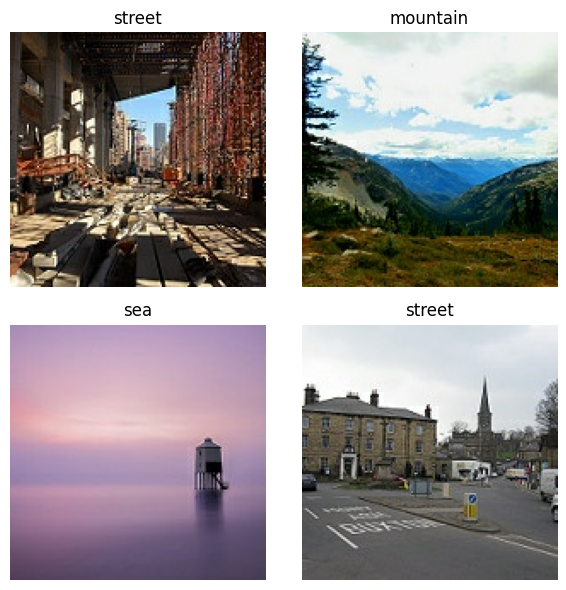

Dataset sample visualization completed.


In [23]:
import matplotlib.pyplot as plt
import numpy as np

#---- 2. QUICK SAMPLE IMAGES VISUALIZATION ----#
for images, labels in train_ds.take(1):
    img_batch = images.numpy()
    label_batch = labels.numpy()
    break

plt.figure(figsize=(6, 6))
for i in range(4):
    ax = plt.subplot(2, 2, i + 1)
    plt.imshow(img_batch[i])
    class_idx = np.argmax(label_batch[i])
    plt.title(class_names[class_idx])
    plt.axis("off")

plt.tight_layout()
plt.show()
print("Dataset sample visualization completed.")

# D. Convolutional Neural Network (CNN) Model. #

##**LEVEL 1: Learning basic features (edges, outlines, angles).**##

## 4.1 (Layer 1): Input layer. ##

In [24]:
#-- Import Liarary. --#
import tensorflow as tf
from tensorflow.keras import layers
#---- Input Layer ----#
input_layer = layers.Input(shape=(150, 150, 3)) #-- Each image has 150x150x3 = 67500 pixels with three channels. --#
print("Input layer defined successfully with shape:", input_layer.shape)

Input layer defined successfully with shape: (None, 150, 150, 3)


## 4.2 (Layer 2): First Convolutional Layer. ##

In [25]:
#-- First Convolutional Layer. --#
conv_1 = layers.Conv2D(32, (3, 3), padding='same')
x1 = conv_1(input_layer)

In [26]:
x1

<KerasTensor shape=(None, 150, 150, 32), dtype=float32, sparse=False, ragged=False, name=keras_tensor_1>

## 4.3 (Layer 3): First Activation Layer. ##

In [27]:
relu_1 = layers.Activation('relu')
x2 = relu_1(x1)

In [28]:
x2

<KerasTensor shape=(None, 150, 150, 32), dtype=float32, sparse=False, ragged=False, name=keras_tensor_2>

## 4.4 (Layer 4): First Pooling Layer. ##

In [29]:
# Cell 4: First Pooling Layer
pool_1 = layers.MaxPooling2D((2, 2))
x3 = pool_1(x2)

In [30]:
x3

<KerasTensor shape=(None, 75, 75, 32), dtype=float32, sparse=False, ragged=False, name=keras_tensor_3>

## **LEVEL 2: Learn more complex structures and shapes.** ##

## 4.5 (Layer 5): Second Convolutional Layer. ##

In [31]:
# Cell 5: Second Convolutional Layer
conv_2 = layers.Conv2D(64, (3, 3), padding='same')
x4 = conv_2(x3)

In [32]:
x4

<KerasTensor shape=(None, 75, 75, 64), dtype=float32, sparse=False, ragged=False, name=keras_tensor_4>

## 4.6 (Layer 6): Second Activation Layer (ReLU). ##

In [33]:
relu_2 = layers.Activation('relu')
x5 = relu_2(x4)

In [34]:
x5

<KerasTensor shape=(None, 75, 75, 64), dtype=float32, sparse=False, ragged=False, name=keras_tensor_5>

## 4.7 (Layer 7): Batch Normalization Layer. ##

In [35]:
bn_2 = layers.BatchNormalization()
x6 = bn_2(x5)

In [36]:
x6

<KerasTensor shape=(None, 75, 75, 64), dtype=float32, sparse=False, ragged=False, name=keras_tensor_6>

Why Batch Normalization starts from Layer 2: Batch Normalization is introduced from the second convolutional block onward to stabilize internal covariate shift as feature representations grow deeper and more complex, while the initial layer focuses on extracting raw low-level spatial features.

## 4.8 (Layer 8): Second Pooling Layer. ##

In [37]:
pool_2 = layers.MaxPooling2D((2, 2))
x7 = pool_2(x6)

In [38]:
x7

<KerasTensor shape=(None, 37, 37, 64), dtype=float32, sparse=False, ragged=False, name=keras_tensor_7>

## **LEVEL 3: Learn other relationship.** ##

## 4.9 (Layer 9): Third Convolutional layer. ##

In [39]:
conv_3 = layers.Conv2D(128, (3, 3), padding='same')
x8 = conv_3(x7)

In [40]:
x8

<KerasTensor shape=(None, 37, 37, 128), dtype=float32, sparse=False, ragged=False, name=keras_tensor_8>

## 4.10 (Layer 10): Third Activation Layer. ##

In [41]:
relu_3 = layers.Activation('relu')
x9 = relu_3(x8)

In [42]:
x9

<KerasTensor shape=(None, 37, 37, 128), dtype=float32, sparse=False, ragged=False, name=keras_tensor_9>

## 4.11 (Layer 11): Dropout Layer. ##

In [43]:
drop_3 = layers.Dropout(0.3)
x10 = drop_3(x9)

In [44]:
x10

<KerasTensor shape=(None, 37, 37, 128), dtype=float32, sparse=False, ragged=False, name=keras_tensor_10>

## 4.12 (Layer 12): Third Pooling Layer. ##

In [45]:
pool_3 = layers.MaxPooling2D((2, 2))
x11 = pool_3(x10)

In [46]:
x11

<KerasTensor shape=(None, 18, 18, 128), dtype=float32, sparse=False, ragged=False, name=keras_tensor_11>

## 4.13 (Layer 13): Flattening Layer. ##

In [47]:
flatten_layer = layers.Flatten()
x12 = flatten_layer(x11)

In [48]:
x12

<KerasTensor shape=(None, 41472), dtype=float32, sparse=False, ragged=False, name=keras_tensor_12>

## 4.14 (layer 14): Fully Connected Layer. ##

In [49]:
dense_1 = layers.Dense(128, activation='relu')
x13 = dense_1(x12)

In [50]:
x13

<KerasTensor shape=(None, 128), dtype=float32, sparse=False, ragged=False, name=keras_tensor_13>

## 4.15 (Layer 15): Output Layer. ##

In [51]:
output_layer = layers.Dense(6, activation='softmax')
outputs = output_layer(x13)

In [52]:
outputs

<KerasTensor shape=(None, 6), dtype=float32, sparse=False, ragged=False, name=keras_tensor_14>

## Asemble Final Model and Print Summary. ##

In [53]:
from tensorflow.keras import models

model = models.Model(inputs=input_layer, outputs=outputs, name="Base_CNN_Model")
model.summary()

Model: "Base_CNN_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 150, 150, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     5,308,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,402,822 (20.61 MB)

 Trainable params: 5,402,694 (20.61 MB)

 Non-trainable params: 128 (512.00 B)

# E. Training and Evaluation. #

## 5.1 Training Model. ##

In [59]:
#---- SECTION 5.1: ADAPTIVE CNN TRAINING ----#
import tensorflow as tf
#-- 1. Compile the model. --#
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
# 2. Save the best model based on validation loss
checkpoint = tf.keras.callbacks.ModelCheckpoint(filepath="Base_CNN_Model.keras", monitor="val_loss", mode="min", save_best_only=True, verbose=1)
# 3. Stop automatically when validation loss stops improving
early_stopping = tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=7, min_delta=0.001, restore_best_weights=True, verbose=1)
# 4. Reduce learning rate when learning plateaus. --#
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", mode="min", factor=0.5, patience=3, min_lr=1e-7, verbose=1)
#-- Train without a fixed epoch limit. --#

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=1000,  # Safety limit, not a target
    callbacks=[
        checkpoint,
        reduce_lr,
        early_stopping
    ]
)

print("Training completed.")

Epoch 1/1000
352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7280 - loss: 0.7416
Epoch 1: val_loss improved from None to 0.67995, saving model to Base_CNN_Model.keras

Epoch 1: finished saving model to Base_CNN_Model.keras
352/352 ━━━━━━━━━━━━━━━━━━━━ 1066s 3s/step - accuracy: 0.7556 - loss: 0.6789 - val_accuracy: 0.7575 - val_loss: 0.6800 - learning_rate: 0.0010
Epoch 2/1000
352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8236 - loss: 0.4754
Epoch 2: val_loss did not improve from 0.67995
352/352 ━━━━━━━━━━━━━━━━━━━━ 809s 2s/step - accuracy: 0.8319 - loss: 0.4543 - val_accuracy: 0.7328 - val_loss: 0.7790 - learning_rate: 0.0010
Epoch 3/1000
352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8691 - loss: 0.3588
Epoch 3: val_loss did not improve from 0.67995
352/352 ━━━━━━━━━━━━━━━━━━━━ 766s 2s/step - accuracy: 0.8781 - loss: 0.3370 - val_accuracy: 0.6210 - val_loss: 1.3892 - learning_rate: 0.0010
Epoch 4/1000
352/352 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9031 - lo

KeyboardInterrupt: 

## 5.2 Evaluation Model. ##

In [61]:
import tensorflow as tf
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

model_path = "Base_CNN_Model.keras"
best_model = tf.keras.models.load_model(model_path)

best_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

val_loss, val_accuracy = best_model.evaluate(val_ds)
print(f"\nValidation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

y_true = []
y_pred = []

for images, labels in val_ds:
    preds = best_model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

print("\nClassification Report on Validation Set:")
print(classification_report(y_true, y_pred))

87/87 ━━━━━━━━━━━━━━━━━━━━ 52s 582ms/step - accuracy: 0.8671 - loss: 0.6144

Validation Loss: 0.6144
Validation Accuracy: 86.71%

Classification Report on Validation Set:
              precision    recall  f1-score   support

           0       0.87      0.83      0.85       415
           1       0.95      0.97      0.96       447
           2       0.81      0.81      0.81       488
           3       0.84      0.80      0.82       500
           4       0.84      0.88      0.86       455
           5       0.88      0.91      0.90       479

    accuracy                           0.87      2784
   macro avg       0.87      0.87      0.87      2784
weighted avg       0.87      0.87      0.87      2784



## 5.3 Testing. ##

In [62]:
# 1. Evaluate the model on the Test Set
test_loss, test_accuracy = best_model.evaluate(test_ds)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

# 2. Get detailed predictions on the Test Set for report generation
y_true_test = []
y_pred_test = []

for images, labels in test_ds:
    preds = best_model.predict(images, verbose=0)
    y_true_test.extend(np.argmax(labels.numpy(), axis=1))
    y_pred_test.extend(np.argmax(preds, axis=1))

# Print full classification report
print("\nClassification Report on Test Set:")
print(classification_report(y_true_test, y_pred_test))

94/94 ━━━━━━━━━━━━━━━━━━━━ 781s 8s/step - accuracy: 0.8277 - loss: 0.8400

Test Loss: 0.8400
Test Accuracy: 82.77%

Classification Report on Test Set:
              precision    recall  f1-score   support

           0       0.82      0.76      0.79       437
           1       0.93      0.96      0.94       474
           2       0.79      0.77      0.78       553
           3       0.80      0.76      0.78       525
           4       0.81      0.87      0.84       510
           5       0.82      0.85      0.84       501

    accuracy                           0.83      3000
   macro avg       0.83      0.83      0.83      3000
weighted avg       0.83      0.83      0.83      3000

